# Análisis numérico de descargas

Cada sección corresponde a una etapa del análisis (ver la tabla de etapas en `CLAUDE.md`).
Los métodos están en `metodos/` y las etapas, en `analisis/`; acá solo se llaman y se muestran los resultados.
Unidades internas: bytes y segundos. 1 MB = 10⁶ B.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analisis.preparacion import cargar_corrida, preparar_corrida

corridas = pd.read_csv("datos/corridas.csv")
corridas[["corrida", "banda", "ubicacion", "carga_extra", "tamano_bytes", "senal_dbm", "wget_vel"]]

,corrida,banda,ubicacion,carga_extra,tamano_bytes,senal_dbm,wget_vel
0,C1,5 GHz,cerca del router (4 m),ninguna,2927861760,-54.0,NaN
1,C2,5 GHz,cerca del router (4 m),Netflix en el TV,2927861760,-55.0,10.2 MB/s
2,C3,2.4 GHz,cerca del router (4 m),ninguna,2927861760,-42.0,8.53 MB/s
3,C4,2.4 GHz,"balcón (6 m), puerta cerrada",ninguna,2927861760,NaN,4.30 MB/s


## Etapa 0: preparación

Para cada corrida:
1. `B(t) = C(t) − C(t₀)`, con `C` el contador del sistema.
2. Tasa de fondo `r_f`: pendiente por mínimos cuadrados en los primeros y en los últimos 30 s (cada tramo por separado, se promedian).
3. Bytes de la descarga: `B_d(t) = B(t) − r_f·t`.
4. `v∞`: pendiente de `B_d` entre el 20 % y el 80 % de los bytes.
5. `v = dB_d/dt` con la fórmula de 3 puntos; `t_ini` y `t_fin` son el primer y el último instante con `v > 0,1·v∞`.
6. Sobrecarga de protocolo: `p = (B_d(t_fin) − S) / S`.

In [2]:
resultados = {}
for _, fila in corridas.iterrows():
    t, B = cargar_corrida(f"datos/{fila.corrida.lower()}.csv")
    resultados[fila.corrida] = {"t": t, "B": B, "S": fila.tamano_bytes,
                                **preparar_corrida(t, B, fila.tamano_bytes)}

tabla = pd.DataFrame({
    c: {
        "h medio [s]": r["h"],
        "desvío de h [s]": r["desvio_h"],
        "r_f inicio [B/s]": r["r_inicio"],
        "r_f final [B/s]": r["r_final"],
        "r_f [B/s]": r["r_f"],
        "v∞ [MB/s]": r["v_inf"] / 1e6,
        "t_ini [s]": r["t_ini"],
        "t_fin [s]": r["t_fin"],
        "duración [s]": r["t_fin"] - r["t_ini"],
        "B_d(t_fin) [B]": r["B_d"][r["i_fin"]],
        "p [%]": 100 * r["p"],
    }
    for c, r in resultados.items()
})
tabla.style.format("{:.6g}")

,C1,C2,C3,C4
h medio [s],0.1,0.1,0.1,0.1
desvío de h [s],7.92502e-05,8.20781e-05,0.000110703,7.6824e-05
r_f inicio [B/s],737.467,1021.86,689.983,278.932
r_f final [B/s],1118.65,217.501,1081.78,576.205
r_f [B/s],928.06,619.682,885.882,427.568
v∞ [MB/s],11.5788,11.2702,9.43216,4.67295
t_ini [s],32.6001,35.6001,34.9001,33.7003
t_fin [s],299,309.4,361.5,682.2
duración [s],266.4,273.8,326.6,648.5
B_d(t_fin) [B],3.07638e+09,3.07582e+09,3.07469e+09,3.07473e+09


### Control contra `wget`

`wget` informa la velocidad media de toda la descarga, `S / duración`, en unidades de 2²⁰ B aunque diga "MB/s".
Si la duración medida es correcta, las dos columnas tienen que coincidir. (C1 no tiene el dato.)

In [3]:
pd.DataFrame({
    "S / duración [MiB/s]": {c: r["S"] / (r["t_fin"] - r["t_ini"]) / 2**20 for c, r in resultados.items()},
    "wget": corridas.set_index("corrida")["wget_vel"],
})

,S / duración [MiB/s],wget
C1,10.481331,NaN
C2,10.198044,10.2 MB/s
C3,8.549373,8.53 MB/s
C4,4.305669,4.30 MB/s


### Bytes de la descarga en cada corrida

Las líneas punteadas marcan `t_ini` y `t_fin`. Mismo eje vertical en las cuatro, para comparar.

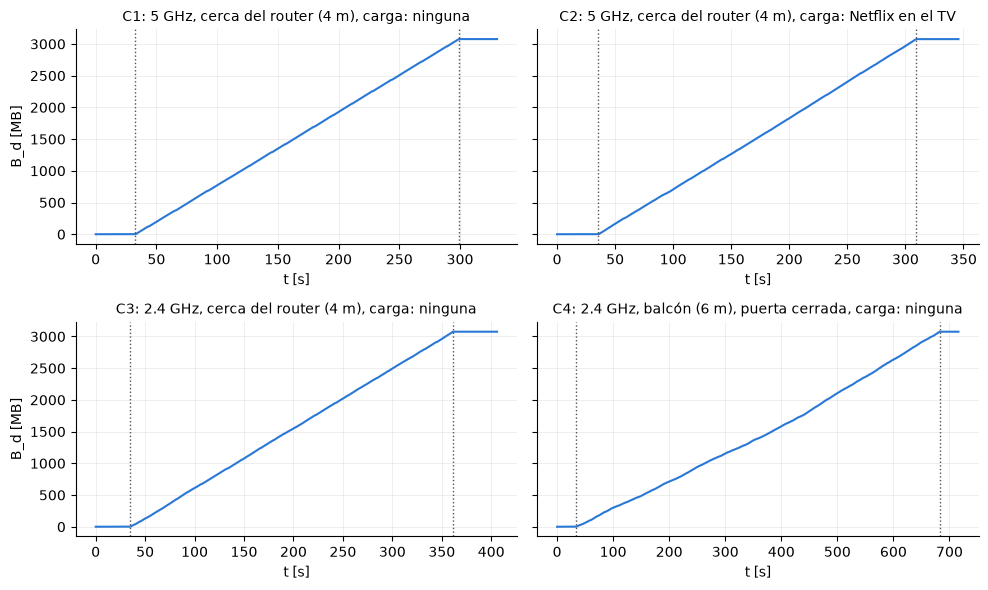

In [4]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for eje, (c, r) in zip(ejes.flat, resultados.items()):
    eje.plot(r["t"], r["B_d"] / 1e6, color="#2a78d6", linewidth=1.5)
    for t_marca in (r["t_ini"], r["t_fin"]):
        eje.axvline(t_marca, color="#52514e", linewidth=1, linestyle=":")
    fila = corridas.set_index("corrida").loc[c]
    eje.set_title(f"{c}: {fila.banda}, {fila.ubicacion}, carga: {fila.carga_extra}", fontsize=10)
    eje.set_xlabel("t [s]")
    eje.grid(alpha=0.3, linewidth=0.5)
    eje.spines[["top", "right"]].set_visible(False)
for eje in ejes[:, 0]:
    eje.set_ylabel("B_d [MB]")
fig.tight_layout()

## Etapa 1: velocímetro

`v = dB_d/dt` con las fórmulas de 3 y de 5 puntos, con el paso de la captura (h = 0,1 s) y con h = 1 s (una lectura de cada 10).
La referencia es `v∞` de la etapa 0. En el tramo de régimen (entre el 20 % y el 80 % de los bytes) se mide:
- **media** de `v − v∞`: si el velocímetro está corrido;
- **desvío** de `v − v∞`: cuánto oscila la lectura de una muestra a otra.

Si las diferencias fueran solo ruido de medición en B (blanco, de desvío σ), el desvío de v sería 0,71·σ/h con 3 puntos y 0,95·σ/h con 5 puntos (ver `tests/test_velocimetro.py`): pasar de h = 0,1 a 1 s lo dividiría por 10, y 5 puntos daría un 34 % más que 3 puntos.

In [5]:
from analisis.velocimetro import velocidades, error_en_regimen

filas = []
for c, r in resultados.items():
    for k in (1, 10):
        vel = velocidades(r["t"], r["B_d"], k)
        for formula in ("v3", "v5"):
            media, desvio = error_en_regimen(vel[formula], r["v_inf"], vel["B_d"])
            filas.append({
                "corrida": c,
                "h [s]": round(vel["h"], 3),
                "fórmula": "3 puntos" if formula == "v3" else "5 puntos",
                "media [MB/s]": media / 1e6,
                "desvío [MB/s]": desvio / 1e6,
                "desvío / v∞ [%]": 100 * desvio / r["v_inf"],
            })
velocimetro = pd.DataFrame(filas)
velocimetro.pivot(index="corrida", columns=["h [s]", "fórmula"],
                  values=["media [MB/s]", "desvío [MB/s]", "desvío / v∞ [%]"]).round(3)

media [MB/s]                            desvío [MB/s]           \
h [s]            0.1               1.0                    0.1            
fórmula     3 puntos 5 puntos 3 puntos 5 puntos      3 puntos 5 puntos   
corrida                                                                  
C1            -0.051   -0.052   -0.052   -0.052         1.938    2.079   
C2            -0.022   -0.022   -0.026   -0.028         2.016    2.213   
C3            -0.022   -0.022   -0.016   -0.016         2.183    2.451   
C4             0.058    0.058    0.058    0.057         1.479    1.591   

                          desvío / v∞ [%]                             
h [s]        1.0                      0.1               1.0           
fórmula 3 puntos 5 puntos        3 puntos 5 puntos 3 puntos 5 puntos  
corrida                                                               
C1         0.927    1.088          16.735   17.958    8.006    9.398  
C2         0.929    1.080          17.890   19.632    8.246    9.584  
C3         0.949    1.119          23.144   25.982   10.064   11.861  
C4         0.919    0.985          31.652   34.053   19.656   21.074

In [6]:
# Cuánto cambia el desvío: al pasar de h = 0,1 a 1 s, y de 3 a 5 puntos.
d = velocimetro.set_index(["corrida", "h [s]", "fórmula"])["desvío [MB/s]"].unstack(["h [s]", "fórmula"])
pd.DataFrame({
    "h 0,1 → 1 s (3 p.)": d[(0.1, "3 puntos")] / d[(1.0, "3 puntos")],
    "h 0,1 → 1 s (5 p.)": d[(0.1, "5 puntos")] / d[(1.0, "5 puntos")],
    "5 p. / 3 p. (h = 0,1)": d[(0.1, "5 puntos")] / d[(0.1, "3 puntos")],
    "5 p. / 3 p. (h = 1)": d[(1.0, "5 puntos")] / d[(1.0, "3 puntos")],
}).round(2)

,"h 0,1 → 1 s (3 p.)","h 0,1 → 1 s (5 p.)","5 p. / 3 p. (h = 0,1)",5 p. / 3 p. (h = 1)
corrida,,,,
C1,2.09,1.91,1.07,1.17
C2,2.17,2.05,1.10,1.16
C3,2.30,2.19,1.12,1.18
C4,1.61,1.62,1.08,1.07


### Velocímetro de C1 en un minuto de régimen

Las cuatro combinaciones en la misma escala vertical. La línea punteada es `v∞`.

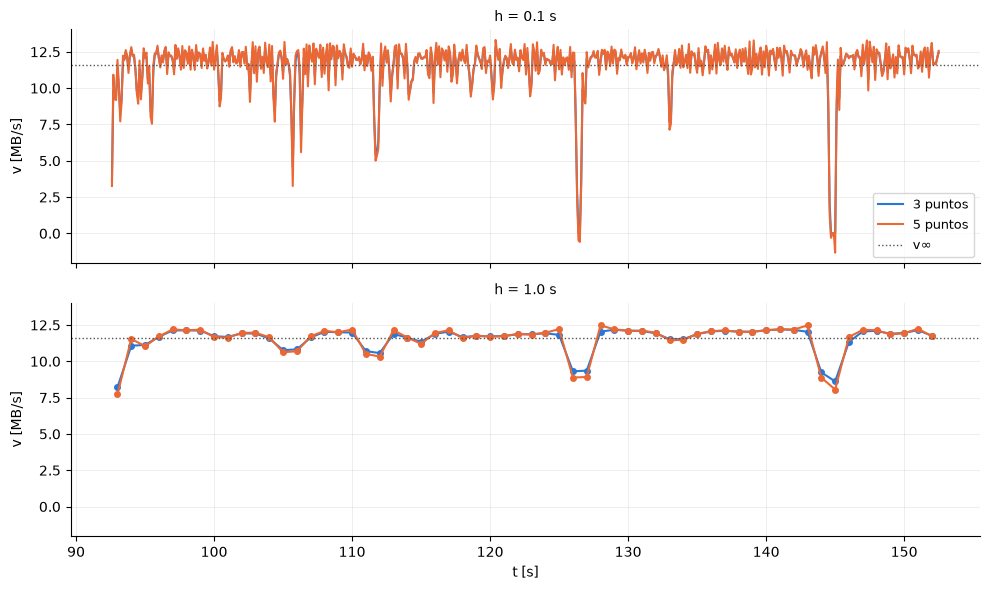

In [7]:
r = resultados["C1"]
desde, hasta = r["t_ini"] + 60, r["t_ini"] + 120

fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
for eje, k in zip(ejes, (1, 10)):
    vel = velocidades(r["t"], r["B_d"], k)
    ventana = (vel["t"] >= desde) & (vel["t"] <= hasta)
    marcador = "o" if k > 1 else None
    eje.plot(vel["t"][ventana], vel["v3"][ventana] / 1e6, color="#2a78d6", linewidth=1.5,
             marker=marcador, markersize=4, label="3 puntos")
    eje.plot(vel["t"][ventana], vel["v5"][ventana] / 1e6, color="#eb6834", linewidth=1.5,
             marker=marcador, markersize=4, label="5 puntos")
    eje.axhline(r["v_inf"] / 1e6, color="#52514e", linewidth=1, linestyle=":", label="v∞")
    eje.set_title(f"h = {vel['h']:.1f} s", fontsize=10)
    eje.set_ylabel("v [MB/s]")
    eje.grid(alpha=0.3, linewidth=0.5)
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].legend(loc="lower right", fontsize=9)
ejes[-1].set_xlabel("t [s]")
fig.tight_layout()

### Caídas de velocidad en régimen

Con h = 0,1 s y 3 puntos: mediana de v y porcentaje de lecturas por debajo de 0,5·v∞ y de 0,9·v∞.

In [8]:
from analisis.preparacion import tramo_regimen

caidas = {}
for c, r in resultados.items():
    vel = velocidades(r["t"], r["B_d"])
    v = vel["v3"][tramo_regimen(vel["B_d"])]
    caidas[c] = {
        "v∞ [MB/s]": r["v_inf"] / 1e6,
        "mediana de v [MB/s]": np.median(v) / 1e6,
        "v < 0,5·v∞ [%]": 100 * np.mean(v < 0.5 * r["v_inf"]),
        "v < 0,9·v∞ [%]": 100 * np.mean(v < 0.9 * r["v_inf"]),
    }
pd.DataFrame(caidas).T.round(2)

,v∞ [MB/s],mediana de v [MB/s],"v < 0,5·v∞ [%]","v < 0,9·v∞ [%]"
C1,11.58,12.00,2.75,8.43
C2,11.27,11.81,3.23,11.71
C3,9.43,10.06,4.54,19.74
C4,4.67,4.90,6.51,30.72


### Qué muestra la etapa 1

- **Sin sesgo.** La media de `v − v∞` es menor al 1 % de v∞ en las cuatro corridas y con las cuatro combinaciones. Es lo esperable: el promedio de la derivada en un tramo es (casi) la pendiente media de B_d en ese tramo.
- **El desvío no es ruido de medición.** Con h = 1 s el desvío baja, pero de 1,6 a 2,3 veces y no 10, y 5 puntos da entre un 7 y un 18 % más que 3 puntos, no un 34 %. El modelo de ruido blanco en B no describe estos datos.
- **Lo que se ve son caídas reales.** La velocidad pasa casi todo el tiempo un poco por encima de v∞ y cada tanto cae durante unas décimas de segundo, a veces hasta 0: la descarga se frena de verdad (Wi-Fi, TCP). Por eso la mediana de v supera a v∞, que es la velocidad *media* e incluye las caídas. Con h = 1 s cada caída se promedia con el resto del segundo y se ve atenuada.
- **Más caídas con peor enlace.** El porcentaje de lecturas bajo 0,9·v∞ crece de C1 a C2, a C3 y a C4, en el mismo orden en que baja v∞.
- **3 puntos con h = 1 s es la combinación de menor desvío en las cuatro corridas.** El orden más alto de 5 puntos solo ayuda si B es suave; acá no lo es, y sus coeficientes más grandes amplifican más las variaciones. El orden teórico de cada fórmula se verifica en `tests/test_derivacion.py`, con funciones de derivada exacta conocida.